# 02 - Modelling
We train two kinds of model:
- **history model**: uses recent ridership (lags and rolling means). Most accurate, but needs recent data.
- **planning model**: uses only things known in advance (route, calendar, schedule, weather). This is the one the app will use.

Plan: split by time -> baselines -> 4 algorithms (plus an average of the two best) inside a Pipeline -> tune with 5-fold time-series CV -> pick on validation -> test once.

Shared helper code (loading, splitting, pipeline building, metrics) lives in `utils.py` so every notebook uses exactly the same steps.

In [1]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neighbors import KNeighborsRegressor
from utils import HISTORY, TARGET, load_data, make_pipeline, planning_features, scores, split_by_days

sns.set_theme(style="whitegrid")
df = load_data()
target = TARGET

## 1. Time-ordered split (70 / 15 / 15)
We split by **whole days**, oldest to newest. Shuffling would let the model see the future while predicting the past. All routes of the same hour always land in the same split.

In [2]:
train, val, test = split_by_days(df)
for name, part in [("train", train), ("val", val), ("test", test)]:
    print(name, len(part), "rows,", part["transit_timestamp"].dt.normalize().nunique(), "days,",
          part["transit_timestamp"].min().date(), "to", part["transit_timestamp"].max().date())

train 44928 rows, 78 days, 2025-01-13 to 2025-07-14
val 9792 rows, 17 days, 2025-07-15 to 2025-09-04
test 9792 rows, 17 days, 2025-09-05 to 2025-09-28


## 2. Features
Dropped from the model inputs:
- `transit_timestamp`, `window_id`: identifiers, not real features.
- `month`: only a few months exist, so it acts like a window label.
- `gtfs_n_directions`: equals 2 for every route.
- Six weather columns that copy each other or add noise (`apparent_temperature`, `relative_humidity_2m`, `dew_point_2m`, `pressure_msl`, `cloud_cover`, `wind_gusts_10m`). Notebook 05 showed that keeping only temperature, precipitation, snowfall and wind speed gives lower error on seasons the model has not seen.

In [3]:
planning_cols = planning_features(df)
variants = {"planning": planning_cols, "history": planning_cols + HISTORY}
print(len(variants["planning"]), "planning features,", len(variants["history"]), "history features")

20 planning features, 25 history features


## 3. Metrics and baselines
- **MAE**: average error in riders (our main metric, easy to explain to planners).
- **RMSE**: like MAE but punishes big misses more.
- **R2**: share of the variation explained (1 is perfect, 0 is no better than guessing the average).

Baselines (a model must beat these to be worth anything):
- *history baseline*: ridership at the same hour one week ago (`lag_168h`).
- *planning baseline*: the training average for that route, hour and weekday/weekend.

In [4]:
keys = ["bus_route", "hour", "is_weekend"]
typical = train.groupby(keys)["ridership"].mean().rename("typical").reset_index()

def planning_baseline(part):
    merged = part[keys].merge(typical, on=keys, how="left")
    return merged["typical"].fillna(train["ridership"].mean()).to_numpy()

def history_baseline(part):
    return part["lag_168h"].to_numpy()

rows = []
for name, part in [("train", train), ("val", val)]:
    rows.append({"baseline": "planning (route-hour average)", "split": name, **scores(part[target], planning_baseline(part))})
    rows.append({"baseline": "history (same hour last week)", "split": name, **scores(part[target], history_baseline(part))})
pd.DataFrame(rows).round(2)

,baseline,split,MAE,RMSE,R2
0,planning (route-hour average),train,59.60,102.58,0.93
1,history (same hour last week),train,61.31,116.24,0.91
2,planning (route-hour average),val,82.66,151.65,0.84
3,history (same hour last week),val,57.29,106.83,0.92


**Reading the baselines:** on validation, last week's value (MAE 57) is a much stronger guess than the route-hour average (MAE 83), because bus ridership repeats weekly. So the history models must beat 57 and the planning models must beat 83.

Test scores for the baselines are saved for the final step, so the test set is only looked at once.

## 4. Pipelines and the algorithms
Each model sits in a scikit-learn `Pipeline`: preprocessing then model. The pipeline is fitted on training data only, so nothing from validation or test leaks into scaling or encoding.

- `bus_route` and `borough` are text, so they are **one-hot encoded** (`handle_unknown="ignore"` lets the app accept a route it never saw).
- Linear Regression and KNN need **scaled** numbers (KNN measures distances, so big columns would dominate). Tree models do not need scaling.
- **Boosting** uses scikit-learn's `HistGradientBoostingRegressor`: the same idea as classic Gradient Boosting (many small trees, each fixing the previous errors) but much faster on 64,000 rows, which lets us search a wider grid.

In [5]:
models = {
    "Linear Regression": (LinearRegression(), True, {}),
    "KNN": (KNeighborsRegressor(), True, {
        "model__n_neighbors": [5, 10, 20, 40],
        "model__weights": ["uniform", "distance"],
    }),
    "Random Forest": (RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1), False, {
        "model__max_depth": [20, None],
        "model__min_samples_leaf": [1, 3],
        "model__max_features": [0.5, 1.0],
    }),
    "Gradient Boosting": (HistGradientBoostingRegressor(random_state=42), False, {
        "model__max_iter": [200, 500],
        "model__learning_rate": [0.05, 0.1],
        "model__max_leaf_nodes": [31, 63],
    }),
}

## 5. Tuning with 5-fold time-series cross-validation
`TimeSeriesSplit` makes every fold train on the past and validate on the next chunk of time. Normal shuffled K-fold would train on future days to predict past days, which gives fake-good scores.

Grid search tries every setting in the grids above and keeps the one with the lowest CV MAE. Linear Regression has no settings to tune, so its grid is empty.

In [6]:
cv = TimeSeriesSplit(n_splits=5)
tuned = {}
cv_scores = {}
best_params = {}

for variant, features in variants.items():
    for name, (model, scale, grid) in models.items():
        pipe = make_pipeline(model, features, scale)
        search = GridSearchCV(pipe, grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
        search.fit(train[features], train[target])
        tuned[(variant, name)] = search.best_estimator_
        cv_scores[(variant, name)] = -search.best_score_
        best_params[(variant, name)] = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
        print(variant, name, "done")

planning Linear Regression done


planning KNN done


/Volumes/DevDrive/Repos/ML-Project/.venv/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


planning Random Forest done


planning Gradient Boosting done
history Linear Regression done


history KNN done


history Random Forest done


history Gradient Boosting done


## 6. An average of the two best models
We also try the simple average of the tuned Random Forest and tuned Gradient Boosting predictions. Averaging two different models often cancels some of their individual mistakes.

In [7]:
for variant, features in variants.items():
    pair = [("rf", clone(tuned[(variant, "Random Forest")])), ("gb", clone(tuned[(variant, "Gradient Boosting")]))]
    average = VotingRegressor(pair).fit(train[features], train[target])
    tuned[(variant, "Average (RF + GB)")] = average
    cv_scores[(variant, "Average (RF + GB)")] = np.nan
    best_params[(variant, "Average (RF + GB)")] = "uses the tuned RF and GB"

rows = []
for (variant, name), estimator in tuned.items():
    features = variants[variant]
    val_scores = scores(val[target], estimator.predict(val[features]))
    rows.append({
        "variant": variant, "model": name,
        "train MAE": mean_absolute_error(train[target], estimator.predict(train[features])),
        "CV MAE": cv_scores[(variant, name)],
        "val MAE": val_scores["MAE"], "val RMSE": val_scores["RMSE"], "val R2": val_scores["R2"],
    })
val_table = pd.DataFrame(rows)
val_table.round(2)

,variant,model,train MAE,CV MAE,val MAE,val RMSE,val R2
0,planning,Linear Regression,119.93,121.02,130.20,180.68,0.77
1,planning,KNN,0.00,80.90,64.33,101.30,0.93
2,planning,Random Forest,17.02,50.86,54.97,92.59,0.94
3,planning,Gradient Boosting,29.68,53.80,55.72,93.39,0.94
4,history,Linear Regression,52.83,59.66,51.51,77.97,0.96
5,history,KNN,0.00,61.24,48.79,73.16,0.96
6,history,Random Forest,13.95,40.00,35.50,55.49,0.98
7,history,Gradient Boosting,25.47,42.08,37.23,57.95,0.98
8,planning,Average (RF + GB),22.36,NaN,54.09,91.44,0.94
9,history,Average (RF + GB),19.24,NaN,35.53,55.38,0.98


In [8]:
pd.Series(best_params).rename("best settings").to_frame()

best settings
planning Linear Regression                                                 {}
         KNN                        {'n_neighbors': 5, 'weights': 'distance'}
         Random Forest      {'max_depth': 20, 'max_features': 0.5, 'min_sa...
         Gradient Boosting  {'learning_rate': 0.05, 'max_iter': 500, 'max_...
history  Linear Regression                                                 {}
         KNN                        {'n_neighbors': 5, 'weights': 'distance'}
         Random Forest      {'max_depth': 20, 'max_features': 0.5, 'min_sa...
         Gradient Boosting  {'learning_rate': 0.05, 'max_iter': 500, 'max_...
planning Average (RF + GB)                           uses the tuned RF and GB
history  Average (RF + GB)                           uses the tuned RF and GB

**Reading the validation table:**
- **Random Forest, Gradient Boosting and their average** are close to each other (planning val MAE 55.0, 55.7 and 54.1; history 35.5, 37.2 and 35.5), and clearly better than KNN and Linear Regression.
- **KNN has a train MAE of 0.0.** With `weights="distance"`, the nearest neighbour of a training row is the row itself, so KNN just memorises the training data. That number is not a real score. Its validation error is much higher, which is **over-fitting**.
- **Linear Regression is worst in the planning variant** (val MAE 130). It can only draw straight lines, but ridership over the day is a double hump. This is **under-fitting**. With history features it does better (51.5) because `lag_168h` alone is almost the answer.
- **Random Forest and Gradient Boosting over-fit somewhat:** train MAE 17 and 30 against validation 55 and 56.

## 7. Model file size, and choosing the final model
The app has to load the saved model, and GitHub rejects files over 100 MB (Streamlit Cloud also has limited memory). A Random Forest stores every node of every tree, so it can become hundreds of MB. So we measure the saved size of each model (compressed, as we would ship it) and only allow models **under 50 MB** to be the final choice. Among the allowed models we pick the lowest validation MAE.

In [9]:
import io

def file_size_mb(estimator):
    buffer = io.BytesIO()
    joblib.dump(estimator, buffer, compress=3)
    return buffer.tell() / 1e6

MAX_MB = 50
val_table["size MB"] = [file_size_mb(tuned[(v, m)]) for v, m in zip(val_table["variant"], val_table["model"])]
val_table[["variant", "model", "val MAE", "size MB"]].round(1)

,variant,model,val MAE,size MB
0,planning,Linear Regression,130.2,0.0
1,planning,KNN,64.3,0.8
2,planning,Random Forest,55.0,109.8
3,planning,Gradient Boosting,55.7,1.5
4,history,Linear Regression,51.5,0.0
5,history,KNN,48.8,2.4
6,history,Random Forest,35.5,110.4
7,history,Gradient Boosting,37.2,1.5
8,planning,Average (RF + GB),54.1,111.4
9,history,Average (RF + GB),35.5,111.9


In [10]:
allowed = val_table[val_table["size MB"] <= MAX_MB]
best_name = {}
for variant in variants:
    part = allowed[allowed["variant"] == variant]
    best_name[variant] = part.loc[part["val MAE"].idxmin(), "model"]
best_name

{'planning': 'Gradient Boosting', 'history': 'Gradient Boosting'}

**Why the size rule matters:** the Random Forest and the average model are about 110 MB even when compressed. That is above GitHub's 100 MB file limit and too heavy for a free web app. Gradient Boosting is 1.5 MB and only about 1.4% worse on validation, so it is the final model for both variants.

## 8. Final evaluation on the test set (done once)
For each variant we refit every model on **train + validation** (more and newer data) with its best settings, then score once on the test set. The model chosen on validation is the final one.

In [11]:
trainval = pd.concat([train, val])
final_models = {}
rows = []

for variant, features in variants.items():
    base = planning_baseline(test) if variant == "planning" else history_baseline(test)
    rows.append({"variant": variant, "model": "Baseline", **scores(test[target], base)})
for (variant, name), estimator in tuned.items():
    features = variants[variant]
    fitted = clone(estimator).fit(trainval[features], trainval[target])
    final_models[(variant, name)] = fitted
    rows.append({"variant": variant, "model": name, **scores(test[target], fitted.predict(test[features]))})

test_table = pd.DataFrame(rows).sort_values(["variant", "MAE"], ascending=[False, True]).reset_index(drop=True)
test_table["chosen"] = [best_name.get(v) == m for v, m in zip(test_table["variant"], test_table["model"])]
test_table.round(2)

,variant,model,MAE,RMSE,R2,chosen
0,planning,Average (RF + GB),63.89,112.62,0.92,False
1,planning,Random Forest,64.02,113.54,0.92,False
2,planning,Gradient Boosting,65.36,113.26,0.92,True
3,planning,Baseline,78.00,129.39,0.89,False
4,planning,KNN,78.20,133.23,0.89,False
5,planning,Linear Regression,127.81,177.47,0.80,False
6,history,Average (RF + GB),38.00,63.47,0.97,False
7,history,Random Forest,38.46,64.29,0.97,False
8,history,Gradient Boosting,38.97,64.96,0.97,True
9,history,KNN,50.46,81.83,0.96,False


**Reading the test results (planning model, the one the app uses):** Gradient Boosting scores MAE **65.4** riders per route-hour, against 78.0 for the baseline: about **16% lower error**. The average route-hour in the test period has 450 riders, so the error is about **14.5%**. R2 is 0.92. Random Forest (64.0) and the average model (63.9) are within 2%, which is smaller than the noise in a 17-day test set, and they are too large to ship.

**History variant:** Gradient Boosting scores **39.0** (about 8.7% of average ridership, R2 0.97) against 54.1 for its baseline: about **28% lower error**.

**KNN** is no better than the baseline in the planning variant, and **Linear Regression** is much worse.

## 9. Over/under-fitting: train vs CV vs validation vs test error

In [12]:
fit_check = val_table[["variant", "model", "train MAE", "CV MAE", "val MAE"]].merge(
    test_table[["variant", "model", "MAE"]].rename(columns={"MAE": "test MAE"}), on=["variant", "model"])
fit_check.round(1)

,variant,model,train MAE,CV MAE,val MAE,test MAE
0,planning,Linear Regression,119.9,121.0,130.2,127.8
1,planning,KNN,0.0,80.9,64.3,78.2
2,planning,Random Forest,17.0,50.9,55.0,64.0
3,planning,Gradient Boosting,29.7,53.8,55.7,65.4
4,history,Linear Regression,52.8,59.7,51.5,53.6
5,history,KNN,0.0,61.2,48.8,50.5
6,history,Random Forest,14.0,40.0,35.5,38.5
7,history,Gradient Boosting,25.5,42.1,37.2,39.0
8,planning,Average (RF + GB),22.4,NaN,54.1,63.9
9,history,Average (RF + GB),19.2,NaN,35.5,38.0


**Over/under-fitting:** train error is well below test error for the tree models (Gradient Boosting about 30 vs 65), so they **over-fit somewhat**, as trees usually do. The gap between validation and test is small, so the model is not tuned to the validation days. Linear Regression has similar errors everywhere (about 120 to 128), which means it **under-fits**: it is too simple, not too flexible.

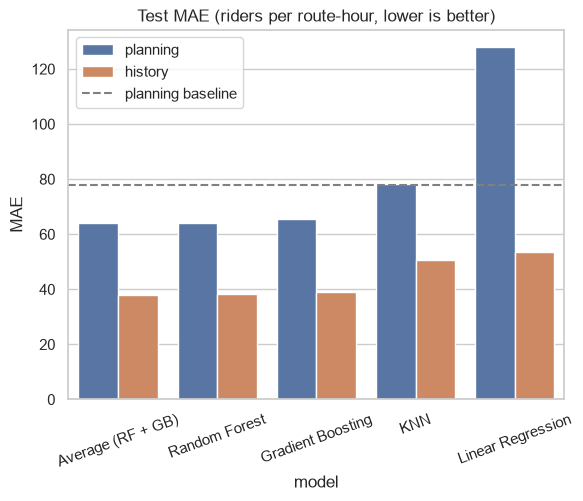

In [13]:
plot_data = test_table[test_table["model"] != "Baseline"]
sns.barplot(data=plot_data, x="model", y="MAE", hue="variant")
plt.axhline(test_table.query("variant == 'planning' and model == 'Baseline'")["MAE"].iloc[0], color="grey", linestyle="--", label="planning baseline")
plt.xticks(rotation=20)
plt.title("Test MAE (riders per route-hour, lower is better)")
plt.legend()
plt.savefig("../figures/08_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Error analysis of the chosen models

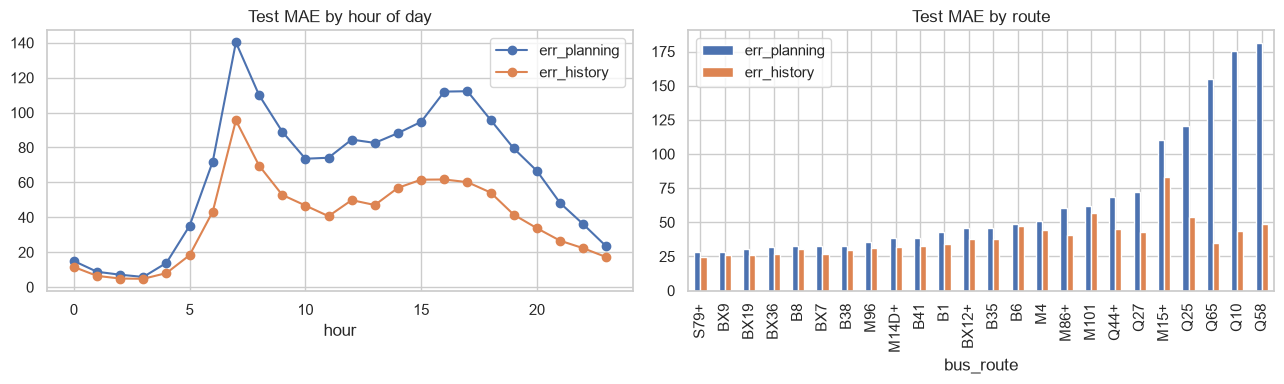

In [14]:
chosen = {v: final_models[(v, best_name[v])] for v in variants}
analysis = test[["transit_timestamp", "bus_route", "hour", "is_weekend", target]].copy()
for v in variants:
    analysis[f"pred_{v}"] = chosen[v].predict(test[variants[v]])
    analysis[f"err_{v}"] = (analysis[target] - analysis[f"pred_{v}"]).abs()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
by_hour = analysis.groupby("hour")[["err_planning", "err_history"]].mean()
by_hour.plot(ax=ax[0], marker="o")
ax[0].set_title("Test MAE by hour of day")
by_route = analysis.groupby("bus_route")[["err_planning", "err_history"]].mean().sort_values("err_planning")
by_route.plot.bar(ax=ax[1])
ax[1].set_title("Test MAE by route")
plt.tight_layout()
plt.savefig("../figures/09_error_by_hour_route.png", dpi=150)
plt.show()

**Errors by hour:** the biggest errors are at the 7 am rush (planning 140, history 96) and the 4-5 pm peak (planning 112). Overnight errors are tiny because ridership itself is tiny.

**Errors by route (important):** four Queens routes, **Q58, Q10, Q65 and Q25**, have planning errors of 120-180 against 25-70 for most others. These four routes are 17% of the test rows but have a planning MAE of 158 against 47 for the other 20 routes. The history model handles them much better (45 vs 38 for the others). The reason is a **level change in the data**: Q58, Q10 and Q65 lost about 35-40% of their weekday riders between June and late August, while Q25 gained about 32% (weekday school-day averages; see notebook 01, section 9). The planning model only knows older months, while the history model sees the recent level. We have not verified the cause (a service change on the Queens network is likely).

**Actual vs predicted (M15+):** both models follow the daily shape and the weekday/weekend difference well. The planning model overshoots the weekday afternoon peak (it predicts about 2,000, actual is 1,200-1,700), while the history model follows the actual curve closely because it can see the recent level.

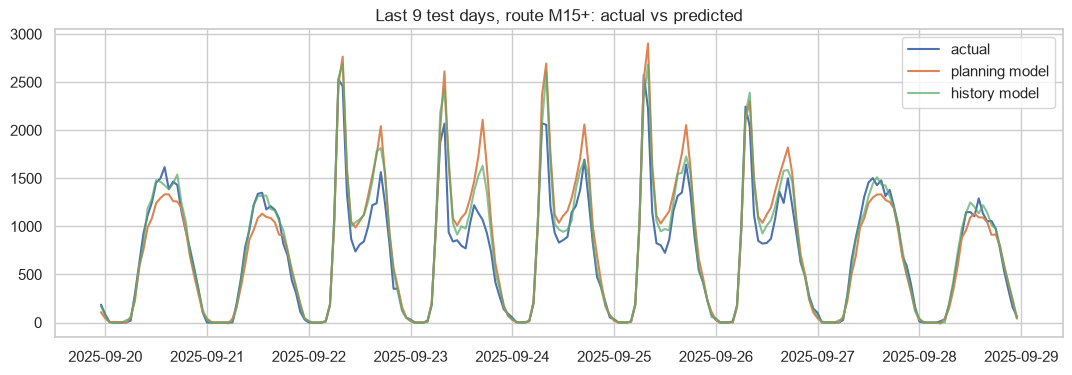

In [15]:
route = analysis.groupby("bus_route")[target].mean().idxmax()
one = analysis[analysis["bus_route"] == route]
one = one[one["transit_timestamp"] >= one["transit_timestamp"].max() - pd.Timedelta(days=9)]
plt.figure(figsize=(13, 4))
plt.plot(one["transit_timestamp"], one[target], label="actual")
plt.plot(one["transit_timestamp"], one["pred_planning"], label="planning model")
plt.plot(one["transit_timestamp"], one["pred_history"], label="history model", alpha=0.7)
plt.title(f"Last 9 test days, route {route}: actual vs predicted")
plt.legend()
plt.savefig("../figures/10_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

**Actual vs predicted (M15+):** both models follow the daily shape and the weekday/weekend difference well. The planning model overshoots the weekday afternoon peak (it predicts about 2,000, actual is 1,200-1,700), while the history model follows the actual curve closely because it can see the recent level.

## 11. Save the final pipelines

In [16]:
import os
os.makedirs("../models", exist_ok=True)
for v in variants:
    joblib.dump(chosen[v], f"../models/{v}_model.joblib", compress=3)
    print(v, "->", best_name[v])

planning -> Gradient Boosting
history -> Gradient Boosting


## Summary of findings
- Tree models (Gradient Boosting, Random Forest) beat the baselines, KNN and Linear Regression. The differences between the tree models are within noise.
- **Final models are Gradient Boosting (1.5 MB each).** Random Forest was about as accurate but 110 MB, too large to deploy.
- **Planning model (no history): MAE 65.4, R2 0.92, about 14.5% of average ridership, 16% better than the baseline (78.0).**
- **History model: MAE 39.0, R2 0.97, about 8.7%, 28% better than its baseline (54.1).**
- The planning model's error is concentrated in four Queens routes whose ridership level changed during the year (158 vs 47 on other routes). Any model trained on earlier months cannot know such a change; recent ridership can.
- The test set is 17 days at the end of September, so small differences (like 64.0 vs 65.4) are not meaningful.
- The planning model was tested with **actual** weather, not a forecast. Real use with forecasts will have somewhat higher error.
- Everything comes from eight 2-week windows in 2025 and one city, so results do not prove the model works for other years or cities.